# Análisis de rutas y experimentos de búsqueda tabú

Este notebook usa los módulos del proyecto (`cargar_datos`, `Zonificar`, `rutas`, `tabu`, `tabu_global`, `Mapeo`) y muestra, en orden: los datos y las zonas, las referencias de comparación, la mejor solución de la búsqueda tabú global, el mapa de rutas y la sensibilidad de los parámetros.

**Cómo usarlo:** ejecuta las celdas en orden (`Run All`). Las distancias salen de las coordenadas del Excel (fórmula de Haversine, en línea recta) y el costo es 0.15 × km. La tabla de sensibilidad se lee de `Resultados_Experimentos.xlsx`; para recalcularla pon `RECALCULAR = True` en la celda correspondiente (tarda unos 8 minutos).

**K** es el número de mejores movimientos admisibles entre los que la búsqueda tabú elige al azar en cada iteración (K = 1 elige siempre el mejor).

In [5]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import IFrame, display

#pip install folium

BASE = Path.cwd()
sys.path.insert(0, str(BASE))
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

from cargar_datos import cargar_datos
from Mapeo import Generar_Mapa
from rutas import (FACTOR_COMBUSTIBLE, costo_ruta, dos_opt, optimo_held_karp,
                   vecino_mas_cercano)
from tabu import resolver_zonas
from tabu_global import busqueda_tabu_global
from Zonificar import asignar_zonas, resumen_zonas

AZUL, NARANJA, GRIS = "#2a78d6", "#eb6834", "#52514e"
print("Carpeta del proyecto:", BASE)

Carpeta del proyecto: c:\Users\MSI\Documents\GitHub\Topicos_IA-trabajos\PROYECTOU2


## 1. Datos y zonas

Cada tienda se asigna al CEDIS más cercano. Las zonas quedan muy desiguales (de 2 a 19 tiendas), lo que más adelante justifica dejar que la búsqueda global reasigne tiendas entre CEDIS.

In [9]:
#pip install openpyxl
nodos, distancias, costos, cedis, tiendas = cargar_datos(BASE / "datos_distribucion_tiendas.xlsx")
zonas = asignar_zonas(distancias, n_cedis=len(cedis))
display(resumen_zonas(zonas, nodos))
print(f"CEDIS: {len(cedis)} | tiendas: {len(tiendas)} | tiendas por zona: {[len(v) for v in zonas.values()]}")

Nodos cargados: 100 | CEDIS: 10 | Tiendas: 90 | distancias desde: excel


,cedis,tiendas,cap_venta,cap_almacen
0,1,2,35734,25838
1,2,19,249060,167940
2,3,5,62614,30628
3,4,8,102935,82675
4,5,8,103820,58036
5,6,2,31260,23460
6,7,12,144626,103240
7,8,8,84331,79811
8,9,13,173727,124047
9,10,13,159850,115750


CEDIS: 10 | tiendas: 90 | tiendas por zona: [2, 19, 5, 8, 8, 2, 12, 8, 13, 13]


## 2. Referencias con zonas fijas

Estas son las referencias contra las que se mide la mejora: el vecino más cercano (heurística voraz), 2-opt, la búsqueda tabú por CEDIS y el **óptimo exacto** de cada ruta (Held-Karp). Todo con las mismas zonas, así que lo único que cambia es el orden de visita dentro de cada ruta.

In [10]:
km = lambda rutas: sum(costo_ruta(distancias, c, r) for c, r in rutas.items())
rutas_nn = {c: vecino_mas_cercano(distancias, c, t) for c, t in zonas.items()}
rutas_2opt = {c: dos_opt(distancias, c, r) for c, r in rutas_nn.items()}
tabu_fijo = resolver_zonas(distancias, zonas, semilla=1)[1]
optimo = sum(optimo_held_karp(distancias, c, t) for c, t in zonas.items())

ref = pd.DataFrame({
    "Método": ["Vecino más cercano", "2-opt", "Tabú por CEDIS (zonas fijas)", "Óptimo exacto (zonas fijas)"],
    "km": [km(rutas_nn), km(rutas_2opt), tabu_fijo, optimo],
})
ref["Combustible"] = FACTOR_COMBUSTIBLE * ref["km"]
ref["Mejora vs vecino más cercano (%)"] = 100 * (ref["km"].iloc[0] - ref["km"]) / ref["km"].iloc[0]
ref["Distancia sobre el óptimo (%)"] = 100 * (ref["km"] - optimo) / optimo
display(ref)

,Método,km,Combustible,Mejora vs vecino más cercano (%),Distancia sobre el óptimo (%)
0,Vecino más cercano,216.50,32.47,0.00,9.98
1,2-opt,198.39,29.76,8.36,0.78
2,Tabú por CEDIS (zonas fijas),197.16,29.57,8.93,0.15
3,Óptimo exacto (zonas fijas),196.86,29.53,9.07,0.00


## 3. Búsqueda tabú global (solución final)

Combina 2-opt dentro de cada ruta con **reubicar** una tienda en la ruta de otro CEDIS. Parámetros: tenencia 60, mínimo 3 tiendas por CEDIS, inicio cercano, hasta 1000 iteraciones y paro tras 150 sin mejora.

In [11]:
res = busqueda_tabu_global(distancias, zonas, tenencia=60, min_tiendas=3, inicio="cercano",
                           semilla=42, max_iter=1000, max_sin_mejora=150, costos=costos)
print(f"Costo inicial: {res.costo_inicial/FACTOR_COMBUSTIBLE:.2f} km  ->  final: {res.mejor_costo/FACTOR_COMBUSTIBLE:.2f} km "
      f"| combustible {res.costo_inicial:.2f} -> {res.mejor_costo:.2f}")
print(f"Iteraciones: {res.iteraciones} | mejor encontrada en la iteración {res.iter_mejor} | {res.tiempo:.1f} s")
ok = sorted(t for r in res.mejores_rutas.values() for t in r) == sorted(tiendas)
print("Las 90 tiendas aparecen exactamente una vez:", ok)

tabla = pd.DataFrame({
    "CEDIS": list(res.mejores_rutas),
    "Tiendas (zona inicial)": [len(zonas[c]) for c in res.mejores_rutas],
    "Tiendas (final)": [len(r) for r in res.mejores_rutas.values()],
    "km finales": [costo_ruta(distancias, c, r) for c, r in res.mejores_rutas.items()],
})
display(tabla)

Costo inicial: 217.04 km  ->  final: 168.59 km | combustible 32.56 -> 25.29
Iteraciones: 351 | mejor encontrada en la iteración 201 | 3.0 s
Las 90 tiendas aparecen exactamente una vez: True


,CEDIS,Tiendas (zona inicial),Tiendas (final),km finales
0,0,2,3,9.96
1,1,19,25,45.81
2,2,5,9,12.61
3,3,8,3,5.73
4,4,8,3,11.25
5,5,2,3,4.36
6,6,12,14,24.19
7,7,8,9,21.32
8,8,13,15,23.82
9,9,13,6,9.54


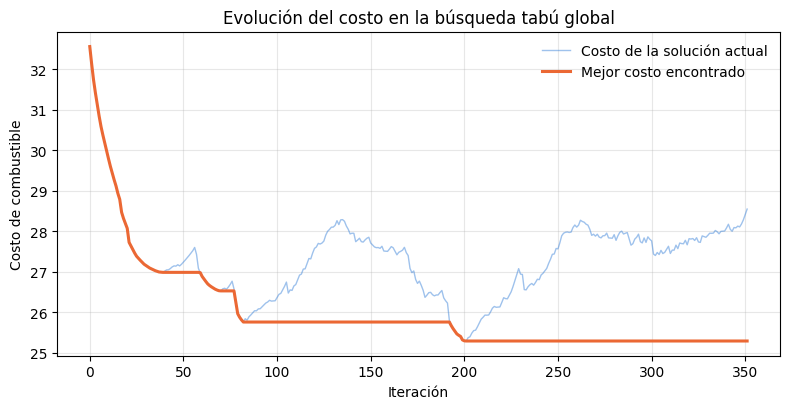

In [12]:
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(res.historial_actual, color=AZUL, alpha=.45, lw=1, label="Costo de la solución actual")
ax.plot(res.historial_mejor, color=NARANJA, lw=2.2, label="Mejor costo encontrado")
ax.set(xlabel="Iteración", ylabel="Costo de combustible", title="Evolución del costo en la búsqueda tabú global")
ax.grid(alpha=.3); ax.legend(frameon=False); plt.tight_layout(); plt.show()

## 4. Rutas sobre las coordenadas reales

A la izquierda, el punto de partida (zonas por CEDIS más cercano, vecino más cercano); a la derecha, el resultado de la búsqueda global.

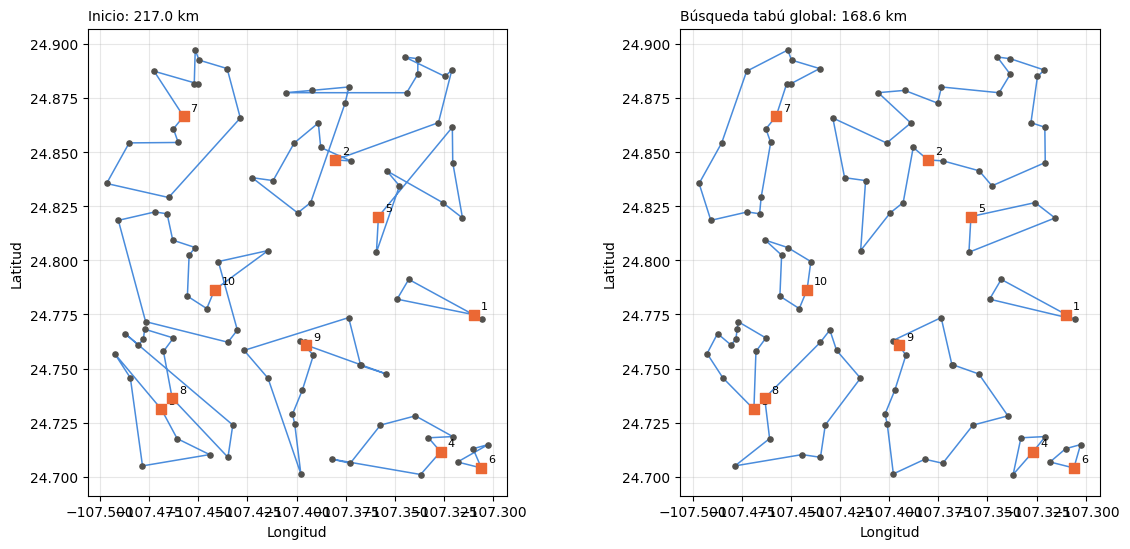

In [13]:
lat, lon = nodos["latitud"].to_numpy(), nodos["longitud"].to_numpy()
def dibujar(ax, rutas, titulo):
    for c, r in rutas.items():
        ax.plot(lon[[c, *r, c]], lat[[c, *r, c]], color=AZUL, lw=1.1, alpha=.85, zorder=2)
    ax.scatter(lon[10:], lat[10:], s=14, color=GRIS, zorder=3)
    ax.scatter(lon[:10], lat[:10], s=60, marker="s", color=NARANJA, zorder=4)
    for c in range(10):
        ax.annotate(str(c + 1), (lon[c], lat[c]), xytext=(5, 4), textcoords="offset points", fontsize=8)
    ax.set_title(titulo, loc="left", fontsize=10)
    ax.set_aspect(1 / np.cos(np.radians(24.8))); ax.grid(alpha=.3)
    ax.set_xlabel("Longitud"); ax.set_ylabel("Latitud")

fig, axs = plt.subplots(1, 2, figsize=(12, 5.6))
dibujar(axs[0], res.rutas_iniciales, f"Inicio: {res.costo_inicial/FACTOR_COMBUSTIBLE:.1f} km")
dibujar(axs[1], res.mejores_rutas, f"Búsqueda tabú global: {res.mejor_costo/FACTOR_COMBUSTIBLE:.1f} km")
plt.tight_layout(); plt.show()

In [15]:
# Mapa interactivo (folium) con la solución global
resultados_mapa = {c: {"Ruta": [c, *r, c], "Costo": costo_ruta(distancias, c, r, costos=costos)}
                   for c, r in res.mejores_rutas.items()}
archivo_mapa = Generar_Mapa(nodos, resultados_mapa, BASE / "Mapa_Rutas_Tabu.html")
display(IFrame(src=archivo_mapa.name, width="100%", height=600))

## 5. Experimentos

Se leen de `Resultados_Experimentos.xlsx`, generado por `experimentos.py` con 1000 iteraciones máximas y paro tras 150 sin mejora. Con límites mucho más bajos (30 iteraciones) la búsqueda global se corta antes de converger y la tabla deja de medir la calidad final.

In [8]:
RECALCULAR = False          # True vuelve a correr todos los experimentos (unos 8 minutos)
ARCHIVO = BASE / "Resultados_Experimentos.xlsx"
if RECALCULAR or not ARCHIVO.exists():
    from experimentos import ejecutar_experimentos
    ejecutar_experimentos(salida=ARCHIVO)
comparacion = pd.read_excel(ARCHIVO, sheet_name="2-opt_vs_tabu")
promedios = pd.read_excel(ARCHIVO, sheet_name="Sensibilidad_promedios")
detalle = pd.read_excel(ARCHIVO, sheet_name="Sensibilidad_detalle")
print("Corridas globales:", len(detalle), "| iteraciones máximas observadas:", detalle["iteraciones"].max())

Corridas globales: 144 | iteraciones máximas observadas: 1000


### 5.1 2-opt contra tabú por CEDIS (zonas fijas)

`mejora_vs_vecino_pct` es la columna que se debe citar en el informe; `ahorro_pct` mide contra el punto de partida de cada fila y con inicio aleatorio queda inflado porque la ruta inicial es mala a propósito.

In [9]:
display(comparacion[["inicio", "metodo", "km_final", "mejora_vs_vecino_pct", "ahorro_pct", "iteraciones_tabu", "tiempo_segundos"]])

,inicio,metodo,km_final,mejora_vs_vecino_pct,ahorro_pct,iteraciones_tabu,tiempo_segundos
0,cercano,2-opt,198.39,8.36,8.36,0,0.01
1,cercano,Tabú 2-opt,196.86,9.07,9.07,679,0.14
2,aleatorio,2-opt,199.00,8.08,49.56,0,0.01
3,aleatorio,Tabú 2-opt,196.97,9.02,50.07,759,0.24


### 5.2 Sensibilidad de la búsqueda global

In [10]:
cercano = promedios[promedios["inicio"] == "cercano"]
tabla = cercano.pivot_table(index=["min_tiendas", "K"], columns="tenencia", values="km_promedio")
tabla.columns = [f"tenencia {t}" for t in tabla.columns]
print("Inicio cercano: km promedio por mínimo de tiendas, K y tenencia")
display(tabla)
mejor = cercano.loc[cercano["km_minimo"].idxmin()]
print(f"Mejor corrida con inicio cercano: {mejor['km_minimo']:.2f} km "
      f"(tenencia {int(mejor['tenencia'])}, K={int(mejor['K'])}, mínimo {int(mejor['min_tiendas'])})")

Inicio cercano: km promedio por mínimo de tiendas, K y tenencia


tenencia 10  tenencia 30  tenencia 60
min_tiendas K                                        
1           1        170.07       166.12       161.90
            10       169.91       165.84       162.45
3           1        179.88       179.88       168.59
            10       177.61       175.26       179.36
5           1        179.93       170.43       170.43
            10       177.26       177.12       180.19

Mejor corrida con inicio cercano: 156.09 km (tenencia 30, K=10, mínimo 1)


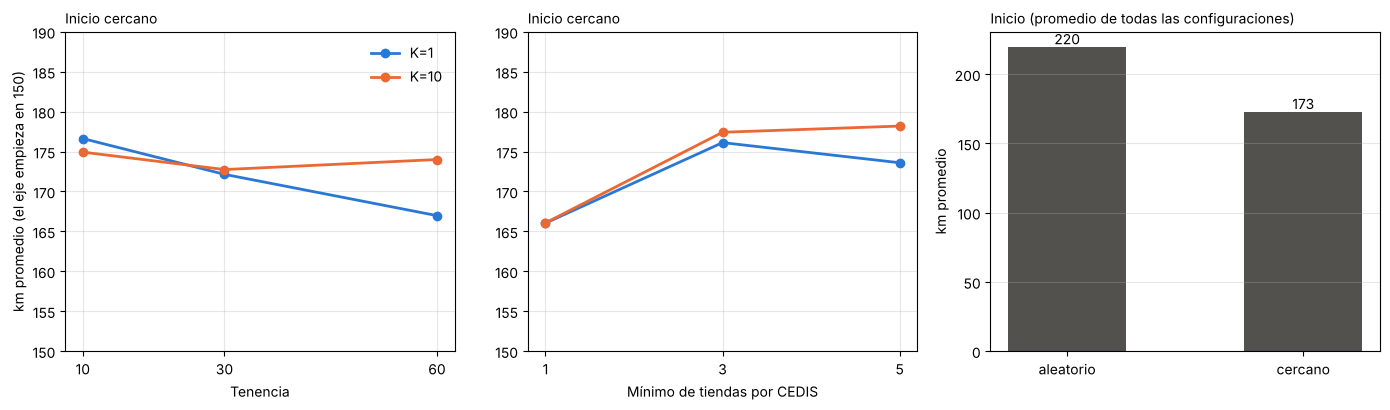

In [11]:
fig, axs = plt.subplots(1, 3, figsize=(14, 4.2))
colores = {1: AZUL, 10: NARANJA}
for k, g in cercano.groupby("K"):
    for ax, col, etq in ((axs[0], "tenencia", "Tenencia"), (axs[1], "min_tiendas", "Mínimo de tiendas por CEDIS")):
        m = g.groupby(col)["km_promedio"].mean()
        ax.plot(m.index, m.values, marker="o", color=colores[k], lw=2, label=f"K={k}")
        ax.set_xlabel(etq); ax.set_xticks(m.index)
for ax in axs[:2]:
    ax.grid(alpha=.3); ax.set_ylim(150, 190)
axs[0].set_ylabel("km promedio (el eje empieza en 150)"); axs[2].set_ylabel("km promedio"); axs[0].set_title("Inicio cercano", loc="left", fontsize=10); axs[0].legend(frameon=False)
axs[1].set_title("Inicio cercano", loc="left", fontsize=10)
ini = promedios.groupby("inicio")["km_promedio"].mean()
axs[2].bar(ini.index, ini.values, color=GRIS, width=.5)
for i, v in enumerate(ini.values):
    axs[2].text(i, v + 2, f"{v:.0f}", ha="center", fontsize=10)
axs[2].set_title("Inicio (promedio de todas las configuraciones)", loc="left", fontsize=10); axs[2].grid(axis="y", alpha=.3)
plt.tight_layout(); plt.show()

## 6. Lectura de resultados

Todo es una sola instancia (90 tiendas, 10 CEDIS) con distancias en línea recta, así que las diferencias pequeñas (de unos 5 km o menos) no deben leerse como una regla general.

- **Zonas fijas:** la búsqueda tabú por CEDIS queda a 0.15 % del óptimo exacto con la tenencia por defecto (7) y lo alcanza con tenencia 10 (196.86 km). 2-opt queda 0.8 % arriba. Con inicio aleatorio, la tabú termina igual de bien (196.97 km), mientras que 2-opt se queda en 199.0 km.
- **Mejora real:** contra el vecino más cercano (216.50 km), la mejora con zonas fijas es de 9 %. Reasignar tiendas entre CEDIS con la búsqueda global, con mínimo 3 tiendas por CEDIS, llega a 168.6 km, una mejora de 22 %. Esa diferencia viene sobre todo de las zonas: el CEDIS más cercano no siempre es el que da la ruta total más corta.
- **Tenencia:** en inicio cercano, el promedio baja de 175.8 km (tenencia 10) a 172.4 (30) y 170.5 (60). Una tenencia corta deja la búsqueda atrapada cerca del inicio.
- **Mínimo de tiendas por CEDIS:** es la regla que más pesa. Sin mínimo (1) el promedio es 166.0 km y la mejor corrida 156.1; con mínimo 3 el promedio es 176.8 y la mejor 168.6. Exigir que todos los CEDIS operen cuesta entre 4 % y 8 % en km. Entre 3 y 5 no hay diferencia clara.
- **K:** elegir entre los 10 mejores movimientos no mejora el promedio con inicio cercano (173.9 km contra 171.9 con K = 1), pero sí abre más variedad entre corridas. Con inicio aleatorio ayuda (214.6 contra 224.7), sin acercarse al inicio cercano.
- **Inicio:** el inicio aleatorio es mucho peor (promedio 219.7 km contra 172.9) aunque se dejen hasta 1000 iteraciones. La búsqueda tabú de corto plazo no escapa de esas soluciones iniciales; una memoria de largo plazo (diversificación) sería la mejora natural y queda como trabajo futuro.
- **Importante:** una tabla de sensibilidad con solo 30 iteraciones máximas corta la búsqueda global antes de converger (necesita entre 200 y 600). Por eso esta tabla se calculó con 1000 iteraciones máximas y paro tras 150 sin mejora.
